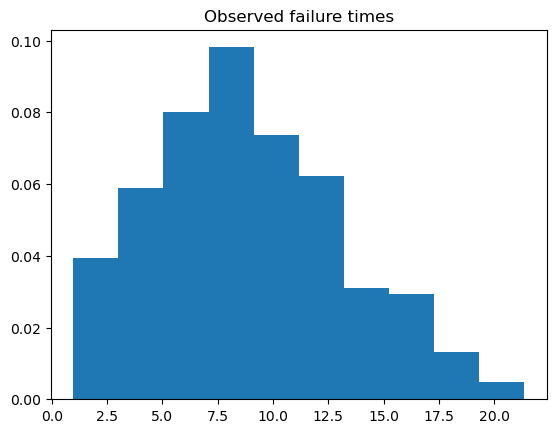

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min

# True parameters (unknown in practice)
k_true = 2.0
lambda_true = 10.0

data = weibull_min.rvs(k_true, scale=lambda_true, size=300)

plt.hist(data, bins=10, density=True)
plt.title("Observed failure times")
plt.show()


True λ: 10.0
Sample mean: 10.818557523637608
Posterior mean: 12.435487729992735
12.207434927697097


Posterior mean λ: 10.11225347050951
True λ: 10.0


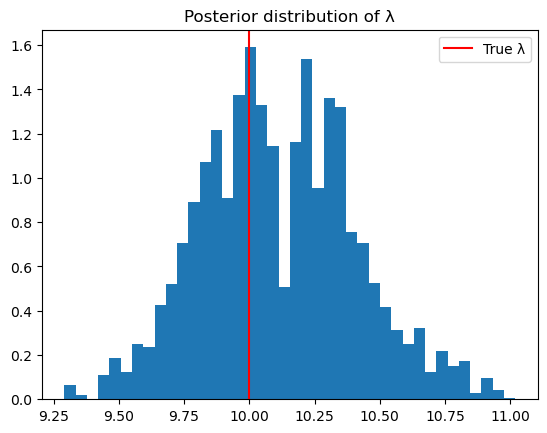

In [26]:
from scipy.stats import gamma

# Prior parameters
a_prior = 2
b_prior = 1   # rate parameter

k_fixed = 2.0

def log_prior(k, lam):
    if k <= 0 or lam <= 0:
        return -np.inf
    return (
        gamma.logpdf(k, a=a_prior, scale=1/b_prior) +
        gamma.logpdf(lam, a=a_prior, scale=1/b_prior)
    )

def log_likelihood(k, lam, data):
    if k <= 0 or lam <= 0:
        return -np.inf
    
    return np.sum(
        np.log(k/lam) +
        (k-1)*np.log(data/lam) -
        (data/lam)**k
    )

def log_posterior(k, lam, data):
    return log_likelihood(k, lam, data) + log_prior(k, lam)

def log_posterior_logscale(theta, k, data):
    lam = np.exp(theta)
    return (
        log_likelihood(k, lam, data)
        + log_prior(k, lam)
        + theta  # Jacobian term: log |dλ/dθ| = log(exp(theta)) = theta
    )
def metropolis(data, n_samples=5000, proposal_sd=0.2):
    samples = []
    theta_current = np.log(5.0)

    for _ in range(n_samples):
        theta_proposal = np.random.normal(theta_current, proposal_sd)

        log_ratio = (
            log_posterior_logscale(theta_proposal, k_fixed, data)
            - log_posterior_logscale(theta_current, k_fixed, data)
        )

        if np.log(np.random.rand()) < log_ratio:
            theta_current = theta_proposal

        samples.append(np.exp(theta_current))

    return np.array(samples)

samples = metropolis(data)

burn_in = 1000
posterior = samples[burn_in:]

print("Posterior mean λ:", posterior.mean())
print("True λ:", lambda_true)

plt.hist(posterior, bins=40, density=True)
plt.axvline(lambda_true, color='r', label="True λ")
plt.legend()
plt.title("Posterior distribution of λ")
plt.show()



Posterior mean λ: 12.44164858890968
True λ: 10.0


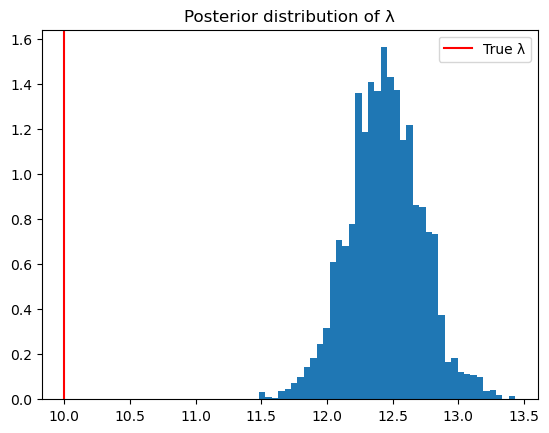

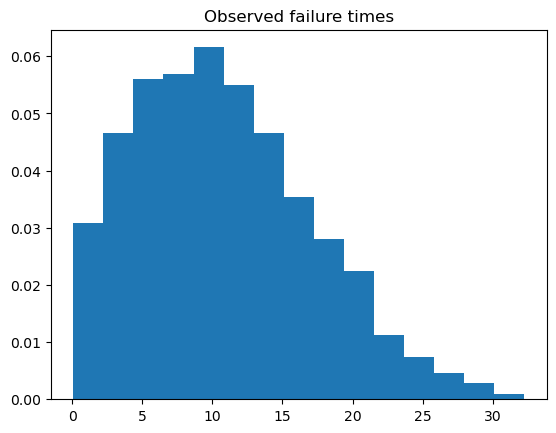

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min

np.random.seed(1)

# True parameters (unknown in practice)
k_true = 1.8
lam_true = 12.0

data = weibull_min.rvs(k_true, scale=lam_true, size=500)

plt.hist(data, bins=15, density=True)
plt.title("Observed failure times")
plt.show()


In [ ]:
from scipy.stats import gamma

def log_prior(k, lam):
    if k <= 0 or lam <= 0:
        return -np.inf
    return (
        gamma.logpdf(k, a=2, scale=1) +
        gamma.logpdf(lam, a=2, scale=1)
    )

def log_likelihood(k, lam, data):
    if k <= 0 or lam <= 0:
        return -np.inf
    
    return np.sum(
        np.log(k/lam) +
        (k-1)*np.log(data/lam) -
        (data/lam)**k
    )

def log_posterior(theta, data):
    k, lam = theta
    return log_likelihood(k, lam, data) + log_prior(k, lam)


def metropolis_2d(data, n_samples=10000, proposal_sd=0.1):
    
    samples = np.zeros((n_samples, 2))
    
    theta_current = np.array([2.0, 10.0])
    
    for i in range(n_samples):
        
        # multiplicative log-normal proposal
        proposal = theta_current * np.exp(
            np.random.normal(0, proposal_sd, size=2)
        )
        
        log_ratio = (
            log_posterior(proposal, data)
            - log_posterior(theta_current, data)
        )
        
        if np.log(np.random.rand()) < log_ratio:
            theta_current = proposal
            
        samples[i] = theta_current
    
    return samples


samples = metropolis_2d(data)

burn = 2000
posterior = samples[burn:]

k_post = posterior[:,0]
lam_post = posterior[:,1]

t_grid = np.linspace(0.01, data.max()*1.5, 200)
R_samples = np.zeros((len(k_post), len(t_grid)))

for i in range(len(k_post)):
    k = k_post[i]
    lam = lam_post[i]
    R_samples[i,:] = np.exp(-(t_grid/lam)**k)

R_lower = np.percentile(R_samples, 2.5, axis=0)
R_median = np.percentile(R_samples, 50, axis=0)
R_upper = np.percentile(R_samples, 97.5, axis=0)

plt.figure()

plt.fill_between(t_grid, R_lower, R_upper, alpha=0.3)
plt.plot(t_grid, R_median, label="Posterior median")

# True reliability curve (since we simulated)
R_true = np.exp(-(t_grid/lam_true)**k_true)
plt.plot(t_grid, R_true, linestyle='--', label="True")

plt.xlabel("Time")
plt.ylabel("Reliability R(t)")
plt.legend()
plt.title("Posterior Reliability Curve with 95% Bands")
plt.show()


print("Posterior mean k:", k_post.mean())
print("True k:", k_true)

print("Posterior mean λ:", lam_post.mean())
print("True λ:", lam_true)

plt.figure()
plt.hist(k_post, bins=40, density=True)
plt.axvline(k_true)
plt.title("Posterior of k")
plt.show()

plt.figure()
plt.hist(lam_post, bins=40, density=True)
plt.axvline(lam_true)
plt.title("Posterior of λ")
plt.show()




plt.figure()
plt.scatter(k_post, lam_post, alpha=0.2, s=5)
plt.xlabel("k")
plt.ylabel("λ")
plt.title("Joint Posterior")
plt.show()







import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.stats import multivariate_normal

mean = np.mean(posterior, axis=0)
cov = np.cov(posterior.T)

levels = [
    chi2.ppf(0.50, df=2),
    chi2.ppf(0.90, df=2),
    chi2.ppf(0.95, df=2)
]


k_grid = np.linspace(k_post.min(), k_post.max(), 200)
lam_grid = np.linspace(lam_post.min(), lam_post.max(), 200)

K, L = np.meshgrid(k_grid, lam_grid)
pos = np.dstack((K, L))

rv = multivariate_normal(mean, cov)
Z = rv.pdf(pos)

plt.figure()
plt.scatter(k_post, lam_post, alpha=0.1, s=5)

plt.contour(K, L, Z,
            levels=sorted(np.max(Z)*np.exp(-np.array(levels)/2)),
            colors=['red','orange','green'])

plt.xlabel("k")
plt.ylabel("lambda")
plt.title("Joint Posterior Credible Regions (Gaussian Approx)")
plt.show()


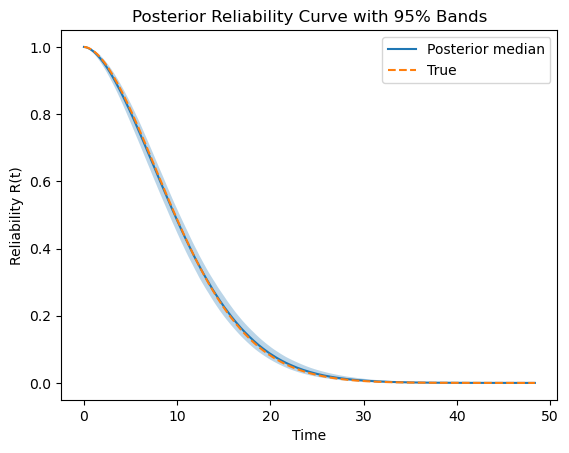

Posterior mean k: 1.7507173475187578
True k: 1.8
Posterior mean λ: 12.002477434669709
True λ: 12.0


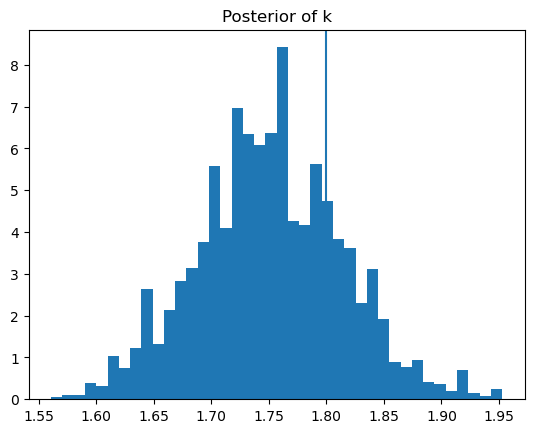

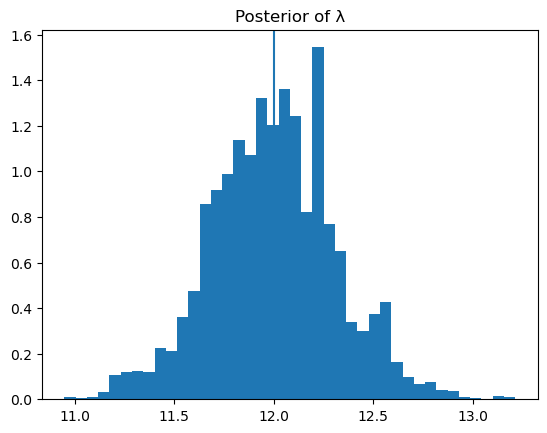

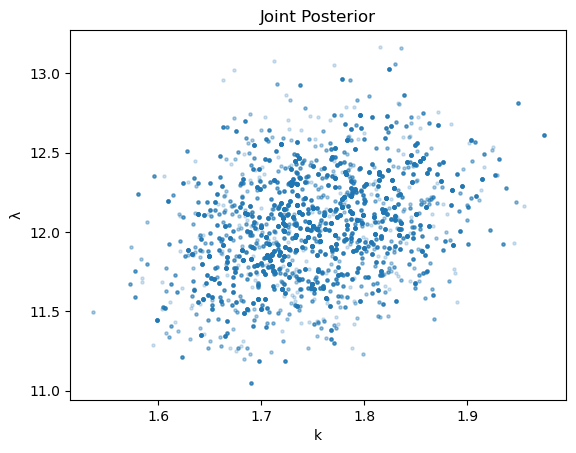

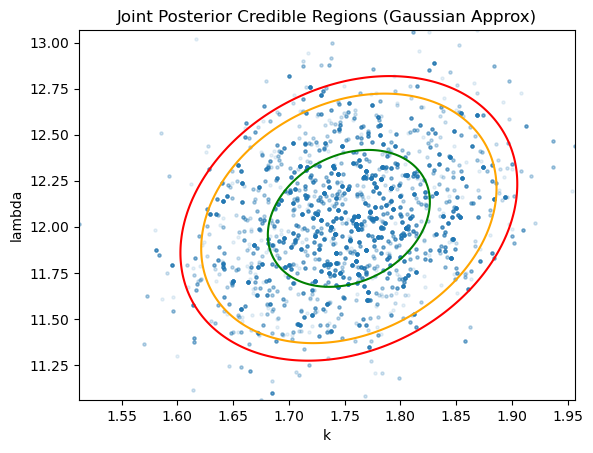

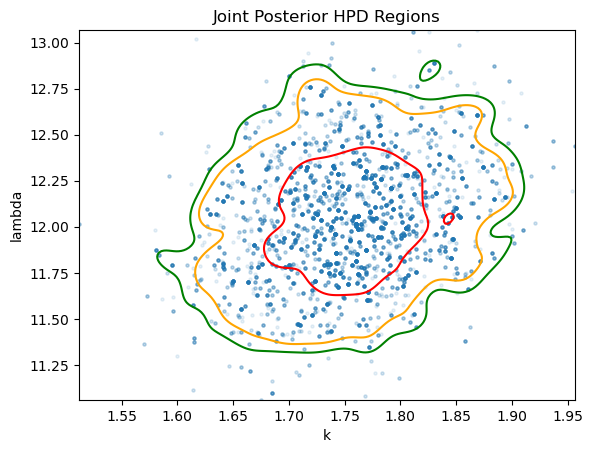

In [ ]:
from scipy.stats import gaussian_kde

kde = gaussian_kde(posterior.T)
Z = kde(pos.reshape(-1,2).T).reshape(K.shape)

Z_flat = Z.flatten()
Z_sorted = np.sort(Z_flat)[::-1]

cumulative = np.cumsum(Z_sorted)
cumulative /= cumulative[-1]

# Find density cutoffs
hpd_50 = Z_sorted[np.searchsorted(cumulative, 0.50)]
hpd_90 = Z_sorted[np.searchsorted(cumulative, 0.90)]
hpd_95 = Z_sorted[np.searchsorted(cumulative, 0.95)]

plt.figure()
plt.scatter(k_post, lam_post, alpha=0.1, s=5)

plt.contour(K, L, Z,
            levels=[hpd_95, hpd_90, hpd_50],
            colors=['green','orange','red'])

plt.xlabel("k")
plt.ylabel("lambda")
plt.title("Joint Posterior HPD Regions")
plt.show()


